# Datos sintéticos de regresión lineal — y = mx + b con ruido

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT

## Enunciado

Generar 100 muestras aleatorias de coordenadas $(x,y)$ sobre una recta $y=mx+b$ con ruido o dispersión, y pintar los puntos.

## Por qué importa este ejercicio

Es el dataset sintético clásico para introducir regresión lineal: se conoce de antemano la recta real, así que después se puede comparar cuánto se acerca un modelo ajustado a los parámetros verdaderos $m$ y $b$. Sin ruido el problema sería trivial, un par de puntos bastarían para reconstruir la recta exacta. El ruido es lo que obliga a **estimar** en vez de resolver un sistema de ecuaciones, que es justamente el punto de la regresión lineal vista en la clase de Regresión Lineal (Parte 1 de la sesión de perceptrón y clasificadores lineales).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

---

## 1. Generar las 100 muestras

Se fija una recta real $y = mx + b$ y se muestrean 100 valores de $x$ de forma uniforme en un rango. El ruido se agrega como una perturbación gaussiana **vertical** sobre cada punto, que es el supuesto estándar en regresión lineal: el error afecta a $y$, no a $x$.

In [2]:
# Parametros de la recta real (los que un modelo de regresion deberia recuperar)
m = 2.5
b = 5.0

# Nivel de dispersion del ruido
sigma_ruido = 2.0

n = 100
x = np.random.uniform(0, 10, n)
ruido = np.random.normal(loc=0.0, scale=sigma_ruido, size=n)
y = m * x + b + ruido

print(f"Recta real: y = {m}x + {b}")
print(f"x: min={x.min():.2f}  max={x.max():.2f}")
print(f"y: min={y.min():.2f}  max={y.max():.2f}")
print(f"Desviacion del ruido, objetivo={sigma_ruido}, medida sobre la muestra={np.std(y - (m*x+b)):.3f}")

Recta real: y = 2.5x + 5.0
x: min=0.06  max=9.87
y: min=4.29  max=31.24
Desviacion del ruido, objetivo=2.0, medida sobre la muestra=1.817


---

## 2. Pintar los puntos

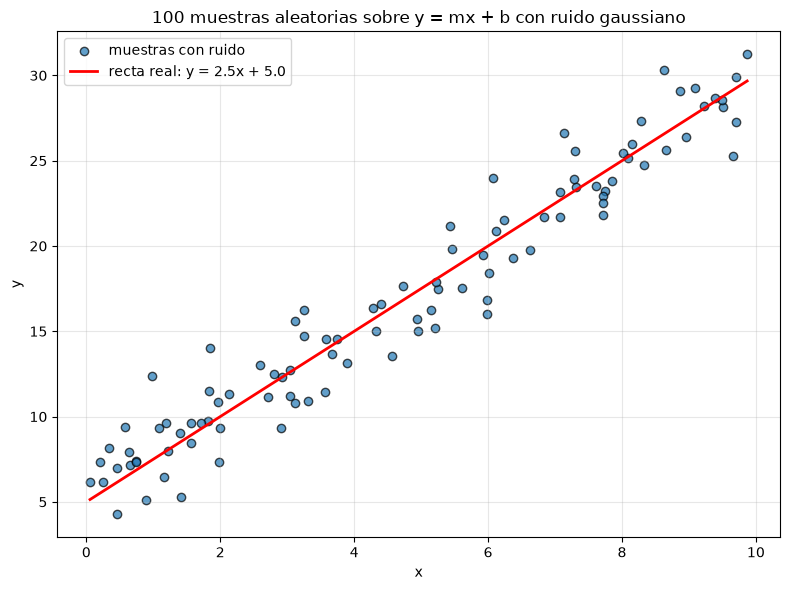

In [3]:
x_linea = np.linspace(x.min(), x.max(), 200)
y_linea = m * x_linea + b

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, edgecolor="k", label="muestras con ruido")
plt.plot(x_linea, y_linea, color="red", linewidth=2, label=f"recta real: y = {m}x + {b}")
plt.xlabel("x")
plt.ylabel("y")
plt.title("100 muestras aleatorias sobre y = mx + b con ruido gaussiano")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

## 3. ¿Qué tan bien se puede recuperar la recta a partir de los puntos?

Para comprobar que el ruido no borra la señal, se ajusta una regresión lineal simple sobre los propios puntos generados y se compara contra los $m$ y $b$ reales.

Real     : m = 2.500   b = 5.000
Estimado : m = 2.408   b = 5.430
Error absoluto: |m - m_hat| = 0.092   |b - b_hat| = 0.430


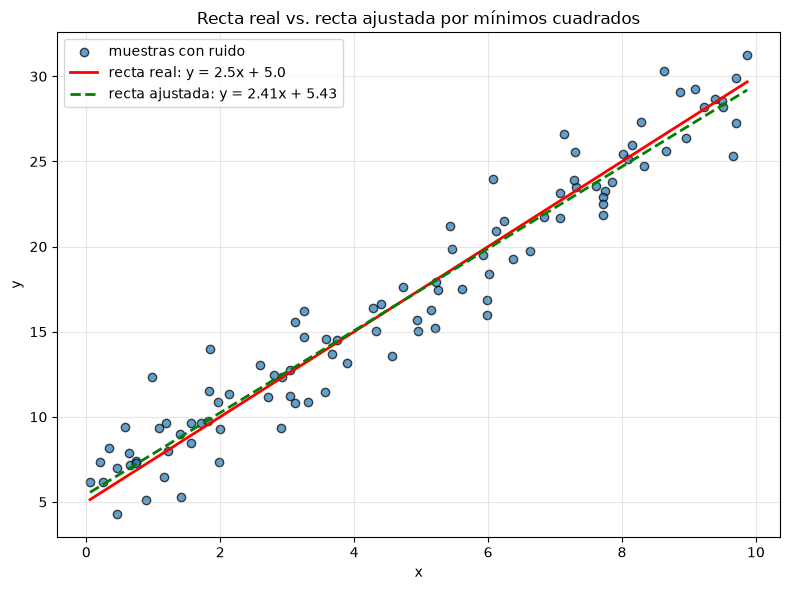

In [4]:
# Regresion lineal por minimos cuadrados (una sola linea con numpy,
# equivalente a resolver la ecuacion normal para un modelo y = m_hat*x + b_hat)
m_hat, b_hat = np.polyfit(x, y, deg=1)

print(f"Real     : m = {m:.3f}   b = {b:.3f}")
print(f"Estimado : m = {m_hat:.3f}   b = {b_hat:.3f}")
print(f"Error absoluto: |m - m_hat| = {abs(m-m_hat):.3f}   |b - b_hat| = {abs(b-b_hat):.3f}")

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, edgecolor="k", label="muestras con ruido")
plt.plot(x_linea, y_linea, color="red", linewidth=2, label=f"recta real: y = {m}x + {b}")
plt.plot(x_linea, m_hat * x_linea + b_hat, color="green", linewidth=2,
         linestyle="--", label=f"recta ajustada: y = {m_hat:.2f}x + {b_hat:.2f}")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Recta real vs. recta ajustada por mínimos cuadrados")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

## 4. Conclusión

Con 100 muestras y un ruido de desviación 2 sobre una recta con pendiente 2.5, el ajuste por mínimos cuadrados recupera $m$ y $b$ con un error menor a una décima. Esa es la idea central de la regresión lineal: aunque cada punto individual está desplazado por el ruido, **el patrón agregado sobre suficientes muestras sigue apuntando a la recta real**, y minimizar el error cuadrático sobre todos los puntos a la vez cancela el ruido en promedio.

Dos parámetros controlan qué tan difícil es el problema:

- **`sigma_ruido`** más alto dispersa los puntos y hace más difícil distinguir la recta a simple vista, aunque con suficientes muestras el ajuste sigue siendo preciso.
- **`n`** más chico (pocas muestras) sí puede arruinar la estimación, incluso con poco ruido, porque hay menos información para promediar.